In [1]:
from typing import List, Dict, Union
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from ccxt.binance import binance
from ccxt.hyperliquid import hyperliquid
from ccxt.lighter import lighter

from siglab_py.util.simple_math import bucket_series, bucketize_val
from siglab_py.util.market_data_util import fetch_candles
from siglab_py.util.analytic_util import compute_candles_stats

VALIDATION_MAX_GAPS = 30

In [2]:
start_date = datetime(2026, 1,1)
end_date = datetime(2026,8,31,0,0,0)
exchange = lighter()
candle_size = "1h"

## Fetch Candles

In [ ]:
all_candles = {}
all_candles_w_ta = {}
all_orderbooks = {}
crypto_tickers = [ "BTC/USDC:USDC", "ETH/USDC:USDC", "SOL/USDC:USDC", "HYPE/USDC:USDC", "DOGE/USDC:USDC", "NEAR/USDC:USDC", "SUI/USDC:USDC", "XLM/USDC:USDC", "ZEC/USDC:USDC", "XMR/USDC:USDC", "TAO/USDC:USDC", "HBAR/USDC:USDC" ]
commodities_tickers = [ "XAU/USDC:USDC", "XAG/USDC:USDC", "WTI/USDC:USDC" ]
tradfi_tickers = [ "AMZN/USDC:USDC", "GOOGL/USDC:USDC", "META/USDC:USDC", "MSFT/USDC:USDC", "MSTR/USDC:USDC", "MU/USDC:USDC", "TSLA/USDC:USDC", "NVDA/USDC:USDC", "SNDK/USDC:USDC", "SPCX/USDC:USDC", "UNITREE/USDC:USDC", "QQQ/USDC:USDC", "SPY/USDC:USDC" ]
fx_tickers = [ "EURUSD/USDC:USDC", "GBPUSD/USDC:USDC", "AUDUSD/USDC:USDC", "NZDUSD/USDC:USDC", "USDJPY/USDC:USDC", "USDCHF/USDC:USDC", "USDCAD/USDC:USDC" ]
tickers = fx_tickers + crypto_tickers + commodities_tickers + tradfi_tickers
for ticker in tickers:
    candles = fetch_candles(
                                                    start_ts=int(start_date.timestamp()), 
                                                    end_ts=int(end_date.timestamp()), 
                                                    exchange=exchange, normalized_symbols=[ticker], 
                                                    candle_size = candle_size, 
                                                    num_candles_limit = 100,
                                                    validation_max_gaps = VALIDATION_MAX_GAPS, # some newly listed FX pairs gaps
                                                    logger = None
                                                )
    pd_candles = candles[ticker]
    all_candles[ticker] = pd_candles
    print(f"Done fetch candles for {ticker}")

    all_orderbooks[ticker] = exchange.fetch_order_book(symbol=ticker)
    all_orderbooks[ticker]['timestamp'] = all_orderbooks[ticker]['timestamp'] if all_orderbooks[ticker]['timestamp'] else datetime.now().timestamp() # in seconds

## Calculate TA

In [ ]:
for ticker in tickers:
    pd_candles = all_candles[ticker]
    compute_candles_stats(
            pd_candles=pd_candles,
            boillenger_std_multiples=2,
            sliding_window_how_many_candles=24,
            validation_max_gaps = VALIDATION_MAX_GAPS, # some newly listed FX pairs gaps
            pypy_compat=True
        )

    all_candles_w_ta[ticker] = pd_candles

    print(f"Done calculate TA for {ticker}")

# ADX

In [6]:
focused = "SOL/USDC:USDC"
pd_candles = all_candles_w_ta[focused]
pd_candles

,exchange,symbol,timestamp_ms,datetime_utc,datetime,open,high,low,close,volume,...,macd_cross_last,macd_cross_open,macd_segment_id,macd_divergence,fib_0.618_short_periods,fib_0.618_long_periods,gap_close_vs_ema,gap_close_vs_ema_percent,close_above_or_below_ema,close_vs_ema_inflection
0,Lighter,SOL/USDC:USDC,1767196800000,2025-12-31 16:00:00+00:00,2026-01-01 00:00:00,125.562,125.719,124.379,124.843,126078.147,...,None,NaN,0,NaN,NaN,NaN,0.000000,0.000000,None,0.0
1,Lighter,SOL/USDC:USDC,1767200400000,2025-12-31 17:00:00+00:00,2026-01-01 01:00:00,124.843,125.261,124.565,125.040,49859.437,...,None,NaN,0,NaN,NaN,NaN,0.181240,0.144946,above,1.0
2,Lighter,SOL/USDC:USDC,1767204000000,2025-12-31 18:00:00+00:00,2026-01-01 02:00:00,125.040,125.500,124.529,124.699,157260.235,...,bearish,125.040,1,---,NaN,NaN,-0.146979,-0.117867,below,NaN
3,Lighter,SOL/USDC:USDC,1767207600000,2025-12-31 19:00:00+00:00,2026-01-01 03:00:00,124.699,125.232,124.397,124.398,190670.157,...,bearish,125.040,1,---,NaN,NaN,-0.412141,-0.331308,below,NaN
4,Lighter,SOL/USDC:USDC,1767211200000,2025-12-31 20:00:00+00:00,2026-01-01 04:00:00,124.398,124.952,123.684,124.257,142679.027,...,bearish,125.040,1,---,NaN,NaN,-0.508890,-0.409546,below,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5895,Lighter,SOL/USDC:USDC,1788418800000,2026-09-03 07:00:00+00:00,2026-09-03 15:00:00,100.841,101.315,100.229,100.337,25003.974,...,bullish,99.168,574,---,100.073582,98.950058,0.266497,0.265602,above,NaN
5896,Lighter,SOL/USDC:USDC,1788422400000,2026-09-03 08:00:00+00:00,2026-09-03 16:00:00,100.337,101.089,100.337,100.586,15549.320,...,bullish,99.168,574,---,100.495676,98.950058,0.474257,0.471494,above,NaN
5897,Lighter,SOL/USDC:USDC,1788426000000,2026-09-03 09:00:00+00:00,2026-09-03 17:00:00,100.586,100.744,100.093,100.113,12933.870,...,bullish,99.168,574,---,100.700100,98.950058,0.001157,0.001155,above,NaN
5898,Lighter,SOL/USDC:USDC,1788429600000,2026-09-03 10:00:00+00:00,2026-09-03 18:00:00,100.113,100.443,99.870,100.388,15660.873,...,bearish,100.113,575,---,100.570320,98.950058,0.254064,0.253082,above,NaN


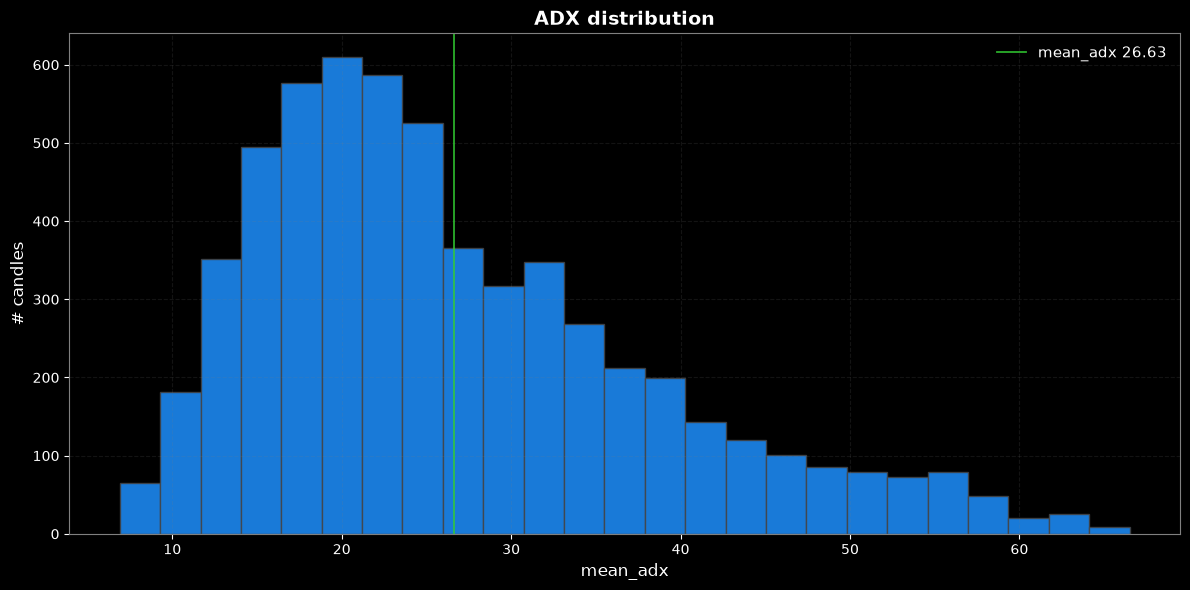

In [7]:
plt.figure(figsize=(12, 6), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

plt.hist(
    pd_candles['adx'],
    bins=25,
    edgecolor='#444444',
    alpha=0.85,
    color='dodgerblue'
)

mean_adx = round(pd_candles['adx'].mean(), 2)
plt.axvline(mean_adx, color='limegreen', linestyle='-', linewidth=1.3, alpha=0.85,
            label=f'mean_adx {mean_adx}')

plt.title('ADX distribution', 
          fontsize=14, fontweight='bold', color='white')
plt.xlabel('mean_adx', fontsize=12, color='white')
plt.ylabel('# candles', fontsize=12, color='white')

plt.grid(True, alpha=0.15, linestyle='--', color='gray')
plt.legend(loc='upper right', frameon=False, fontsize=10.5, labelcolor='white')

ax.tick_params(colors='white', which='both')
ax.spines['bottom'].set_color('gray')
ax.spines['top'].set_color('gray')
ax.spines['left'].set_color('gray')
ax.spines['right'].set_color('gray')

plt.tight_layout()
plt.show()

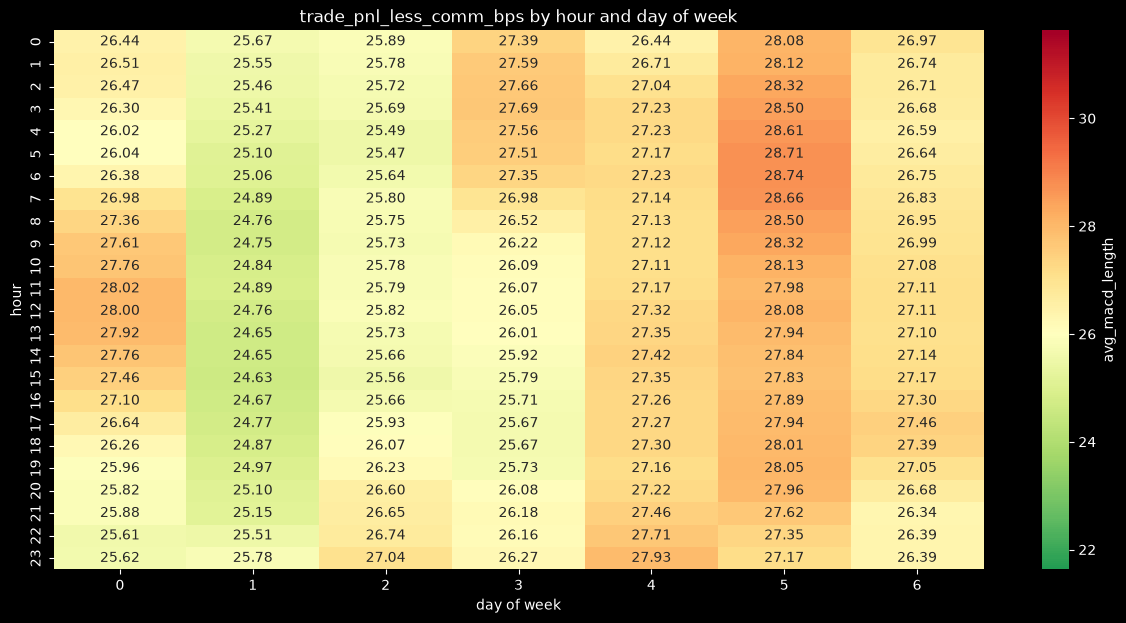

In [21]:
grouped = pd_candles.groupby(['hour', 'dayofweek']).agg(
    mean_adx=('adx', 'mean'),
).reset_index()

heatmap_data = grouped.pivot(index='hour', columns='dayofweek', values='mean_adx')

plt.figure(figsize=(15, 7), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

sns.heatmap(
    heatmap_data, 
    annot=True, 
    fmt='.2f', 
    cmap='RdYlGn_r', 
    vmin=mean_adx-5,
    vmax=mean_adx+5,
    center=26,
    cbar_kws={'label': 'mean_adx by hour and day of week'}
)

ax.set_title('trade_pnl_less_comm_bps by hour and day of week', color='white')
ax.set_xlabel('day of week', color='white')
ax.set_ylabel('hour', color='white')
ax.tick_params(colors='white')
cbar = ax.collections[0].colorbar
cbar.set_label('avg_macd_length', color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

plt.show()